# Building makemore: Part 2 MLP

In [52]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [53]:
# download the names.txt file from github
!curl -O https://raw.githubusercontent.com/karpathy/makemore/master/names.txt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  222k  100  222k    0     0   962k      0 --:--:-- --:--:-- --:--:--  964k


In [54]:
words = open('names.txt', 'r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [55]:
len(words)

32033

In [56]:
wrd = list(set(''.join(words[:3]))).sort()

In [57]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [397]:
# build the dataset

import logging
logging.basicConfig(level=logging.INFO)
block_size = 5 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182400, 5]) torch.Size([182400])
torch.Size([22962, 5]) torch.Size([22962])
torch.Size([22784, 5]) torch.Size([22784])


In [398]:
len_wrds = [len(words[i]) for i in range(len(words))]
import numpy as np

x = [1, 2, 3, 4, 5, 5, 8]

print(np.mean(len_wrds))
print(np.median(len_wrds))
print(np.std(len_wrds))
print(np.var(len_wrds))
print(np.min(len_wrds))
print(np.max(len_wrds))
print(np.percentile(len_wrds, [25, 50, 75]))

6.122217712983486
6.0
1.4403347813133913
2.074564282261095
2
15
[5. 6. 7.]


In [409]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
n_embd = 12
n_hidden = 200
C = torch.randn((27, n_embd), generator=g)
W1 = torch.randn((block_size*n_embd, n_hidden), generator=g) * (5/3) / (block_size*n_embd)**0.5
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, n_hidden), generator=g) * (5/3) / n_hidden**0.5
b2 = torch.randn(n_hidden, generator=g) * 0.01
W3 = torch.randn((n_hidden, 27), generator=g) * 0.01
b3 = torch.zeros(27)
parameters = [C, W1, b1, W2, b2, W3, b3]

In [400]:
sum(p.nelement() for p in parameters) # number of parameters in total

58151

In [410]:
for p in parameters:
  p.requires_grad = True

In [402]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [403]:
lri = []
lossi = []
stepi = []

In [417]:
for i in range(50000):

  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (128,))

  # forward pass
  emb = C[Xtr[ix]] # (128, block_size, n_embd)
  h1 = torch.tanh(emb.view(-1, block_size*n_embd) @ W1 + b1) # (128, n_hidden)
  h2 = torch.tanh(h1 @ W2 + b2) # (128, n_hidden)
  logits = h2 @ W3 + b3 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.005
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0:
    print(f'{i:7d}/200000: {loss.item():.4f}')
  stepi.append(i)
  lossi.append(loss.log10().item())

      0/200000: 1.7859
  10000/200000: 1.8520
  20000/200000: 1.5541
  30000/200000: 1.6535
  40000/200000: 1.6894


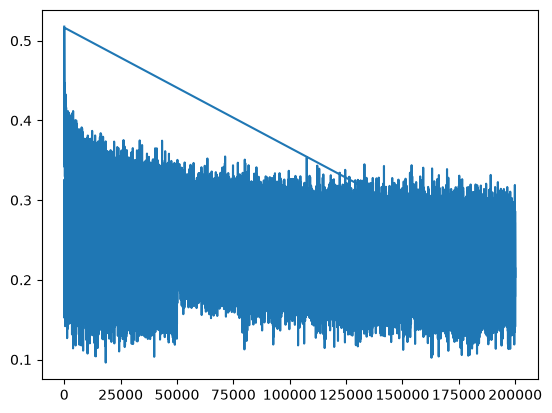

In [418]:
plt.plot(stepi, lossi)

In [419]:
# training loss
emb = C[Xtr] # (N, block_size, n_embd)
h1 = torch.tanh(emb.view(-1, block_size*n_embd) @ W1 + b1)
h2 = torch.tanh(h1 @ W2 + b2)
logits = h2 @ W3 + b3 # (N, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(1.6699, grad_fn=<NllLossBackward0>)

In [420]:
# validation loss
emb = C[Xdev] # (N, block_size, n_embd)
h1 = torch.tanh(emb.view(-1, block_size*n_embd) @ W1 + b1)
h2 = torch.tanh(h1 @ W2 + b2)
logits = h2 @ W3 + b3 # (N, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1090, grad_fn=<NllLossBackward0>)

In [421]:
# test loss
emb = C[Xte] # (N, block_size, n_embd)
h1 = torch.tanh(emb.view(-1, block_size*n_embd) @ W1 + b1)
h2 = torch.tanh(h1 @ W2 + b2)
logits = h2 @ W3 + b3 # (N, 27)
loss = F.cross_entropy(logits, Yte)
loss

tensor(2.1116, grad_fn=<NllLossBackward0>)

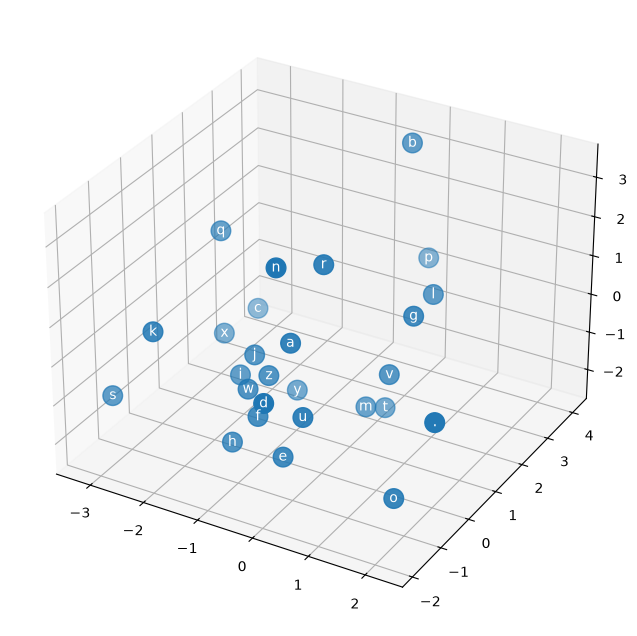

In [422]:
# visualize the 3D embedding matrix C for all characters
plot = plt.figure(figsize=(8,8)).add_subplot(111, projection='3d')
plot.scatter(C[:,0].data, C[:,1].data, C[:,2].data, s=200)
for i in range(C.shape[0]):
    plot.text(C[i,0].item(), C[i,1].item(), C[i,2].item(), itos[i], ha="center", va="center", color='white')

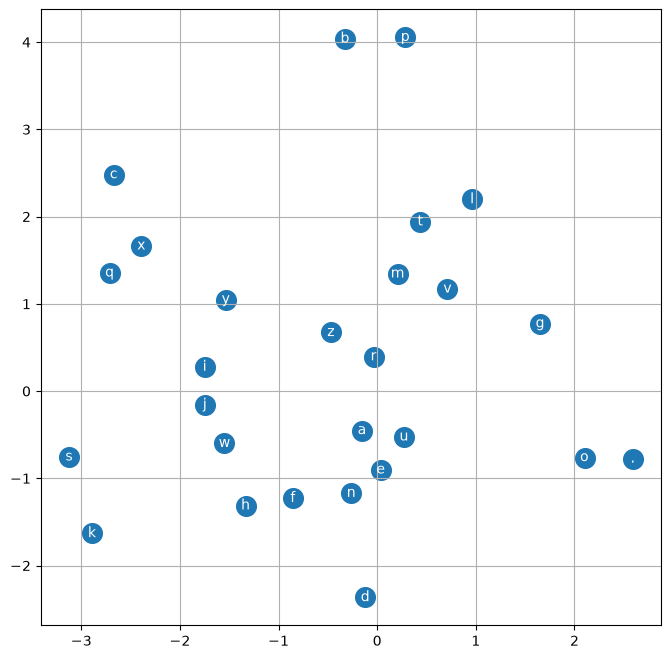

In [376]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [423]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h1 = torch.tanh(emb.view(1, -1) @ W1 + b1)
      h2 = torch.tanh(h1 @ W2 + b2)
      logits = h2 @ W3 + b3
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break

    print(''.join(itos[i] for i in out))

carmah.
ambrie.
khyri.
shreeya.
skarlene.
mahnel.
deliah.
jareei.
nella.
archelina.
siege.
dhanghon.
desira.
shova.
alivebi.
waverly.
jarin.
kaileeniysa.
melayzia.
tetis.
